# Problem 1: Limitations of the Hamming Distance

---

## Background

The Hamming distance is a measure of dissimilarity between two strings of **equal length**. It is defined as the number of positions at which the corresponding symbols differ — or equivalently, the minimum number of single-character substitutions required to transform one string into the other. The concept was introduced by Richard Hamming in the context of error-correcting codes [1].

> **Note on indexing:** Throughout this problem, positions are numbered starting at **1** (i.e., the first character is at position 1).

---

### Example 1: Binary Strings

Consider the two binary strings `1100111001` and `0100010101`.

```
Position:   1  2  3  4  5  6  7  8  9  10
String 1:   1  1  0  0  1  1  1  0  0  1
String 2:   0  1  0  1  0  1  0  1  0  1
            -  +  +  -  -  +  -  -  +  +
```

*(`+` = match, `-` = mismatch)*

There are mismatches at positions **1, 4, 5, 7, and 8**, so the Hamming distance is **5**.

---

### Example 2: DNA Sequences

Consider the two DNA sequences `AGCTAAC` and `AACTCCA`.

```
Position:   1  2  3  4  5  6  7
String 1:   A  G  C  T  A  A  C
String 2:   A  A  C  T  C  C  A
            +  -  +  +  -  -  -
```

*(`+` = match, `-` = mismatch)*

There are mismatches at positions **2, 5, 6, and 7**, so the Hamming distance is **4**.

---

## Tasks

### Task 1: Implementation

Write a function that computes the Hamming distance between two sequences of **equal length**. Your function should be general-purpose: it must not assume any fixed alphabet. Valid inputs include binary strings, DNA sequences, protein sequences, or any other sequence of characters. Your function should raise an appropriate error if the sequences differ in length.

Once your function is implemented, write unit tests to verify its correctness. At minimum, your test suite should cover:

- The binary string example from the background section (`1100111001` vs `0100010101`, expected distance: **5**)
- The DNA example from the background section (`AGCTAAC` vs `AACTCCA`, expected distance: **4**)
- The case where two identical sequences are compared (expected distance: **0**)
- The case where sequences of unequal length are passed (expected: an error is raised)

Report the Big O time and space complexity of your implementation and justify your answer.

In [7]:
# Code present in the src/module_3_assignment/hamming_dist.py file

from module_3_assignment.hamming_dist import hamming_distance

print(hamming_distance("1011101", "1001001"))  # Output: 2
# TC- O(n). and SC- O(1).
# The time complexity is O(n) because we iterate through each character of the strings to compare them. 
# The space complexity is O(1) since we are using a constant amount of space regardless of the input size.



2



### Task 2: Biological Application

Use your Hamming distance function to answer the following question:

> **Is a hippopotamus more closely related to a pig or to a whale?**
 
Use the hemoglobin subunit beta (HBB) protein sequences below. Hemoglobin is a well-established model protein for studying molecular evolution in vertebrates, making it a good candidate for phylogenetic inference.

```
>PIG | A0A8D0NPF5_PIG | Hemoglobin subunit beta
MVHLSAEESAAVLGLQGKVNMVELGGEALGRLLVVYPWTQRFFESFGDLSNADAVMGNPK
VKAHGKKVLQSFSDGLKHLDNLKGTFAKLSELHCDQLHVDPENFRLLGNVIVVILARRFG
NDFNPDLQAAFQKVVAGVANALAHYH

>WHALE | A0A140GN68_KOGSI | Hemoglobin subunit beta
MVHLTAEEKSAVTALWAKVNVEEIGGEALGRLLVVYPWTQRFFEHFGDLSTADAVMKNAS
VKSHGKKVLASFSEGLKHFDNLKGTFAQLSELHCDKLHVDPENFRLLGNVLVVVLARHFG
KEFTPELQTAFQKLVAGVANALAHKYH

>HIPPOPOTAMUS | HBB_HIPAM | Hemoglobin subunit beta
VHLTAEEKDAVLGLWGKVNVQEVGGEALGRLLVVYPWTQRFFESFGDLSSADAVMNNPKV
KAHGKKVLDSFADGLKHLDNLKGTFAALSELHCDQLHVDPENFRLLGNELVVVLARTFGK
EFTPELQAAYQKVVAGVANALAHRYH
```

> Note that the three sequences are not all the same length, and that the hippopotamus sequence begins with `V` rather than the `M` that begins the pig and whale sequences. This kind of discrepancy — where database entries represent slightly different processed forms of the same protein — is common in real bioinformatics work. Before computing any distances, inspect the sequences carefully: consider what region they share, and whether your choice of alignment affects your result.

You may trim or adjust the sequences as you see fit to make them equal length. **Clearly explain your approach and your rationale** — your methodology matters as much as your answer. Consider: does your choice of how to normalize length change the result?



In [8]:
from module_3_assignment.hamming_dist import hamming_distance

hippo_sequence="VHLTAEEKDAVLGLWGKVNVQEVGGEALGRLLVVYPWTQRFFESFGDLSSADAVMNNPKVKAHGKKVLDSFADGLKHLDNLKGTFAALSELHCDQLHVDPENFRLLGNELVVVLARTFGKEFTPELQAAYQKVVAGVANALAHRYH"
pig_sequence="MVHLSAEESAAVLGLQGKVNMVELGGEALGRLLVVYPWTQRFFESFGDLSNADAVMGNPKVKAHGKKVLQSFSDGLKHLDNLKGTFAKLSELHCDQLHVDPENFRLLGNVIVVILARRFGNDFNPDLQAAFQKVVAGVANALAHYH"
whale_sequence="MVHLTAEEKSAVTALWAKVNVEEIGGEALGRLLVVYPWTQRFFEHFGDLSTADAVMKNASVKSHGKKVLASFSEGLKHFDNLKGTFAQLSELHCDKLHVDPENFRLLGNVLVVVLARHFGKEFTPELQTAFQKLVAGVANALAHKYH"

# To make them equal lengths, we can add gaps (represented by '-') to the shorter sequences, in a way so that there's some matching between the sequences. 
# Approach: ( current lengths of sequneces: hippo_sequence= 146, pig_sequence= 146, whale_sequence= 147)
# 1) adding a single gap at the start of hippo_sequence to have a match with the start of whale and pig sequences.(VHL..)
# (updated lengths: hippo_sequence= 147, pig_sequence= 146, whale_sequence= 147)
# 2) adding a single gap before YH at the end of pig_sequence to have a match with the end of hippo and whale sequences. (YH)
# (updated lengths: hippo_sequence= 147, pig_sequence= 147, whale_sequence= 147)
# Now all three sequences have equal lengths of 147.

hippo_sequence= "-VHLTAEEKDAVLGLWGKVNVQEVGGEALGRLLVVYPWTQRFFESFGDLSSADAVMNNPKVKAHGKKVLDSFADGLKHLDNLKGTFAALSELHCDQLHVDPENFRLLGNELVVVLARTFGKEFTPELQAAYQKVVAGVANALAHRYH"
pig_sequence= "MVHLSAEESAAVLGLQGKVNMVELGGEALGRLLVVYPWTQRFFESFGDLSNADAVMGNPKVKAHGKKVLQSFSDGLKHLDNLKGTFAKLSELHCDQLHVDPENFRLLGNVIVVILARRFGNDFNPDLQAAFQKVVAGVANALAH-YH"
whale_sequence= "MVHLTAEEKSAVTALWAKVNVEEIGGEALGRLLVVYPWTQRFFEHFGDLSTADAVMKNASVKSHGKKVLASFSEGLKHFDNLKGTFAQLSELHCDKLHVDPENFRLLGNVLVVVLARHFGKEFTPELQTAFQKLVAGVANALAHKYH"

print( len(hippo_sequence), len(pig_sequence), len(whale_sequence))  # Output: 147 147 147

hamming_dist1= hamming_distance(hippo_sequence, pig_sequence)
hamming_dist2= hamming_distance(hippo_sequence, whale_sequence)

if hamming_dist1 < hamming_dist2:
    print("The hippo sequence is more similar to the pig sequence.")
elif hamming_dist1 > hamming_dist2:
    print("The hippo sequence is more similar to the whale sequence.")
else:
    print("The hippo sequence is equally similar to both the pig and whale sequences.")

# The choice of approach definetely changes the results based on the position and number of gaps added. 
# With the current approach, the hippo sequence is more similar to the pig sequence.

147 147 147
The hippo sequence is more similar to the pig sequence.


---

### Task 3: Reflection

What are some of the limitations you observe for using the Hamming distance for biological sequence comparison? Consider: what kinds of biological events does it fail to account for? What assumptions does it make that may not hold in practice?

---

### Task 4: Phylogenetic Tree Reconstruction via UPGMA

In Task 2 you compared three species. Now scale the analysis up.

Retrieve the hemoglobin subunit beta (HBB) protein sequences for the following species from UniProt using the links below:

| Species | UniProt (FASTA) |
|---|---|
| Human | [P68871](https://rest.uniprot.org/uniprotkb/P68871.fasta) |
| Horse | [P02062](https://rest.uniprot.org/uniprotkb/P02062.fasta) |
| Dog | [P02910](https://rest.uniprot.org/uniprotkb/P02910.fasta) |
| Dolphin (bottlenose) | [P02009](https://rest.uniprot.org/uniprotkb/P02009.fasta) |
| Cow | [P02070](https://rest.uniprot.org/uniprotkb/P02070.fasta) |
| Mouse | [P02088](https://rest.uniprot.org/uniprotkb/P02088.fasta) |
| Hippopotamus | [HBB_HIPAM](https://rest.uniprot.org/uniprotkb/HBB_HIPAM.fasta) |
| Pig | [A0A8D0NPF5](https://rest.uniprot.org/uniprotkb/A0A8D0NPF5.fasta) |
| Whale (sperm) | [A0A140GN68](https://rest.uniprot.org/uniprotkb/A0A140GN68.fasta) |

> **Database note:** Each link downloads the sequence directly in FASTA format via the UniProt REST API.

**Step 1 — Compute the distance matrix.**
Using your Hamming distance function, compute all pairwise distances across the nine sequences. Apply a consistent length-normalization strategy (document your choice). The result should be a 9×9 symmetric matrix stored as a NumPy array.

**Step 2 — UPGMA using SciPy.**
UPGMA (Unweighted Pair Group Method with Arithmetic Mean) is a simple hierarchical clustering algorithm used to build phylogenetic trees from a distance matrix. The algorithm proceeds as follows:

1. Find the pair of sequences $(i, j)$ with the smallest distance.
2. Merge them into a new cluster $u$. Place their common ancestor node at height $d(i,j)/2$.
3. Compute the distance from $u$ to every remaining sequence $k$ as:

$d(u,k) = \frac{|i| \cdot d(i,k) + |j| \cdot d(j,k)}{|i| + |j|}$

where $|i|$ and $|j|$ are the number of sequences in clusters $i$ and $j$ respectively.

4. Remove $i$ and $j$ from the matrix and add $u$. Repeat from step 1 until one cluster remains.

UPGMA is equivalent to average linkage hierarchical clustering, which is available in `scipy.cluster.hierarchy`. Use `linkage()` and `dendrogram()` to run UPGMA on your distance matrix and visualize the resulting tree. Note that `scipy.cluster.hierarchy.linkage()` expects a condensed distance matrix — use `scipy.spatial.distance.squareform()` to convert your square matrix first.

**Step 3 — Evaluate your tree.**
Compare your reconstructed tree to the accepted mammalian phylogeny. Use [TimeTree](https://timetree.org) — enter your nine species names and it will return the consensus phylogenetic tree for those taxa drawn from thousands of published molecular studies. Which relationships does your tree recover correctly? Where does it fail, and why might Hamming distance be responsible?

> **Hint:** Cetaceans (whales and dolphins) are expected to form a clade with hippopotamuses as their closest living relative — closer than any other even-toed ungulate. If your tree does not recover this, consider what properties of Hamming distance might be distorting the result.



### Task 3 Answer 

Hamming distance has a few limitations when comparing biological sequences. First, it only works with sequences of equal length, but DNA and protein sequences are often of different lengths. It also doesn’t directly account for insertions or deletions, which are common in biological sequences and can shift the positions of the remaining characters.

Another limitation is that it treats all positions and substitutions equally, even though some positions are more conserved or important for the protein’s function than others. It also doesn’t consider how changes in the sequence affect biological function. For example, two proteins might have a high Hamming distance but still perform similar functions, while a single change at an important position could significantly affect a protein’s function. So, Hamming distance alone may not always give an accurate picture of how biologically similar two sequences are.


In [9]:
import numpy as np
from module_3_assignment.hamming_dist import hamming_distance

human_sequence="""MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPK
VKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFG
KEFTPPVQAAYQKVVAGVANALAHKYH"""
horse_sequence="""VQLSGEEKAAVLALWDKVNEEEVGGEALGRLLVVYPWTQRFFDSFGDLSNPGAVMGNPKV
KAHGKKVLHSFGEGVHHLDNLKGTFAALSELHCDKLHVDPENFRLLGNVLVVVLARHFGK
DFTPELQASYQKVVAGVANALAHKYH"""
dog_sequence="""MKKLALSLSLVLAFSSATAAFAAIPQKIRIGTDPTYAPFESKNAQGELVGFDIDLAKELC
KRINTQCTFVENPLDALIPSLKAKKIDAIMSSLSITEKRQQEIAFTDKLYAADSRLVVAK
NSDIQPTVASLKGKRVGVLQGTTQETFGNEHWAPKGIEIVSYQGQDNIYSDLTAGRIDAA
FQDEVAASEGFLKQPVGKDYKFGGPAVKDEKLFGVGTGMGLRKEDNELREALNKAFAEMR
ADGTYEKLAKKYFDFDVYGG"""
dolphin_sequence="""SLTKAERTIIGSMWTKISSQADTIGTETLERLFASYPQAKTYFPHFDLNPGSAQLRAHGS
KVLAAVGEAVKSIDNVSAALAKLSELHAYVLRVDPVNFKFLSHCLLVTLASHFPADLTAE
AHAAWDKFLTIVSGVLTEKYR"""
cow_sequence="""MLTAEEKAAVTAFWGKVKVDEVGGEALGRLLVVYPWTQRFFESFGDLSTADAVMNNPKVK
AHGKKVLDSFSNGMKHLDDLKGTFAALSELHCDKLHVDPENFKLLGNVLVVVLARNFGKE
FTPVLQADFQKVVAGVANALAHRYH"""
mouse_sequence="""MVHLTDAEKAAVSCLWGKVNSDEVGGEALGRLLVVYPWTQRYFDSFGDLSSASAIMGNAK
VKAHGKKVITAFNDGLNHLDSLKGTFASLSELHCDKLHVDPENFRLLGNMIVIVLGHHLG
KDFTPAAQAAFQKVVAGVATALAHKYH"""
hippopotamus_sequence="""VHLTAEEKDAVLGLWGKVNVQEVGGEALGRLLVVYPWTQRFFESFGDLSSADAVMNNPKV
KAHGKKVLDSFADGLKHLDNLKGTFAALSELHCDQLHVDPENFRLLGNELVVVLARTFGK
EFTPELQAAYQKVVAGVANALAHRYH"""
pig_sequence="MVHLSAEESAAVLGLQGKVNMVELGGEALGRLLVVYPWTQRFFESFGDLSNADAVMGNPKVKAHGKKVLQSFSDGLKHLDNLKGTFAKLSELHCDQLHVDPENFRLLGNVIVVILARRFGNDFNPDLQAAFQKVVAGVANALAHYH"
whale_sequence="MVHLTAEEKSAVTALWAKVNVEEIGGEALGRLLVVYPWTQRFFEHFGDLSTADAVMKNASVKSHGKKVLASFSEGLKHFDNLKGTFAQLSELHCDKLHVDPENFRLLGNVLVVVLARHFGKEFTPELQTAFQKLVAGVANALAHKYH"

print(len(human_sequence), len(horse_sequence), len(dog_sequence), len(dolphin_sequence), len(cow_sequence), len(mouse_sequence), len(hippopotamus_sequence), len(pig_sequence), len(whale_sequence))  # Output: 147 147 147 147 147 147 146 146 147
# max length is 260
# fixing the lengths of the sequences by adding gaps (represented by '-') at the end to the shorter sequences, bringing every sequence to a length of 264

human_sequence = "MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH_________________________________________________________________________________________________________________"

horse_sequence = "VQLSGEEKAAVLALWDKVNEEEVGGEALGRLLVVYPWTQRFFDSFGDLSNPGAVMGNPKVKAHGKKVLHSFGEGVHHLDNLKGTFAALSELHCDKLHVDPENFRLLGNVLVVVLARHFGKDFTPELQASYQKVVAGVANALAHKYH__________________________________________________________________________________________________________________"

dog_sequence = "MKKLALSLSLVLAFSSATAAFAAIPQKIRIGTDPTYAPFESKNAQGELVGFDIDLAKELCKRINTQCTFVENPLDALIPSLKAKKIDAIMSSLSITEKRQQEIAFTDKLYAADSRLVVAKNSDIQPTVASLKGKRVGVLQGTTQETFGNEHWAPKGIEIVSYQGQDNIYSDLTAGRIDAAFQDEVAASEGFLKQPVGKDYKFGGPAVKDEKLFGVGTGMGLRKEDNELREALNKAFAEMRADGTYEKLAKKYFDFDVYGG"

dolphin_sequence = "SLTKAERTIIGSMWTKISSQADTIGTETLERLFASYPQAKTYFPHFDLNPGSAQLRAHGSKVLAAVGEAVKSIDNVSAALAKLSELHAYVLRVDPVNFKFLSHCLLVTLASHFPADLTAEAHAAWDKFLTIVSGVLTEKYR_______________________________________________________________________________________________________________________"

cow_sequence = "MLTAEEKAAVTAFWGKVKVDEVGGEALGRLLVVYPWTQRFFESFGDLSTADAVMNNPKVKAHGKKVLDSFSNGMKHLDDLKGTFAALSELHCDKLHVDPENFKLLGNVLVVVLARNFGKEFTPVLQADFQKVVAGVANALAHRYH___________________________________________________________________________________________________________________"

mouse_sequence = "MVHLTDAEKAAVSCLWGKVNSDEVGGEALGRLLVVYPWTQRYFDSFGDLSSASAIMGNAKVKAHGKKVITAFNDGLNHLDSLKGTFASLSELHCDKLHVDPENFRLLGNMIVIVLGHHLGKDFTPAAQAAFQKVVAGVATALAHKYH_________________________________________________________________________________________________________________"

hippopotamus_sequence = "VHLTAEEKDAVLGLWGKVNVQEVGGEALGRLLVVYPWTQRFFESFGDLSSADAVMNNPKVKAHGKKVLDSFADGLKHLDNLKGTFAALSELHCDQLHVDPENFRLLGNELVVVLARTFGKEFTPELQAAYQKVVAGVANALAHRYH__________________________________________________________________________________________________________________"

pig_sequence = "MVHLSAEESAAVLGLQGKVNMVELGGEALGRLLVVYPWTQRFFESFGDLSNADAVMGNPKVKAHGKKVLQSFSDGLKHLDNLKGTFAKLSELHCDQLHVDPENFRLLGNVIVVILARRFGNDFNPDLQAAFQKVVAGVANALAHYH__________________________________________________________________________________________________________________"

whale_sequence = "MVHLTAEEKSAVTALWAKVNVEEIGGEALGRLLVVYPWTQRFFEHFGDLSTADAVMKNASVKSHGKKVLASFSEGLKHFDNLKGTFAQLSELHCDKLHVDPENFRLLGNVLVVVLARHFGKEFTPELQTAFQKLVAGVANALAHKYH_________________________________________________________________________________________________________________"

sequence_list = [human_sequence, horse_sequence, dog_sequence, dolphin_sequence, cow_sequence, mouse_sequence, hippopotamus_sequence, pig_sequence, whale_sequence]

dist_matrix= np.zeros((len(sequence_list), len(sequence_list)), dtype=int)

for i in range(len(sequence_list)):
    dist_matrix[i][i] = 0  

for i in range(len(sequence_list)):
    for j in range(i + 1, len(sequence_list)):
        dist = hamming_distance(sequence_list[i], sequence_list[j])
        dist_matrix[i][j] = dist
        dist_matrix[j][i] = dist  

# 9*9 matrix        
print(dist_matrix)




149 148 264 143 147 149 148 146 147
[[  0 136 252 134 139  29 135  31  23]
 [136   0 250 133 131 137  24 132 136]
 [252 250   0 249 253 253 248 251 251]
 [134 133 249   0 133 133 132 133 133]
 [139 131 253 133   0 137 133 135 138]
 [ 29 137 253 133 137   0 136  39  39]
 [135  24 248 132 133 136   0 130 135]
 [ 31 132 251 133 135  39 130   0  33]
 [ 23 136 251 133 138  39 135  33   0]]


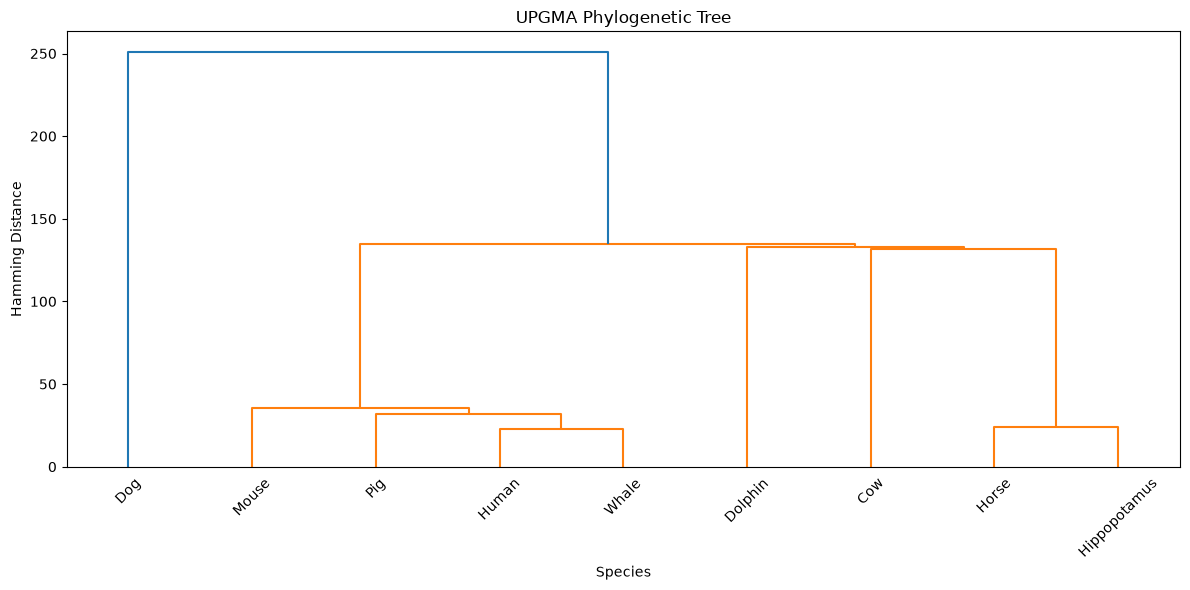

In [10]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt
from scipy.spatial.distance import squareform

condensed_dist_matrix = squareform(dist_matrix)

Z= linkage(condensed_dist_matrix, method='average')

plt.figure(figsize=(12, 6))

dendrogram(Z, labels=["Human", "Horse", "Dog", "Dolphin", "Cow", "Mouse", "Hippopotamus", "Pig", "Whale"], leaf_rotation=45, leaf_font_size=10)

plt.title("UPGMA Phylogenetic Tree")

plt.xlabel("Species")

plt.ylabel("Hamming Distance")

plt.tight_layout()

plt.show()

Which relationships does your tree recover correctly? Where does it fail, and why might Hamming distance be responsible?

Species:
Human- Homo sapiens
Horse- Equus caballus
Dog- Canis lupus familiaris
Dolphin- Tursiops truncatus
Cow- Bos taurus
Mouse- Mus musculus
Hippopotamus- Hippopotamus amphibius
Pig- Sus scrofa
Whale- Balaenoptera musculus

Comparing my UPGMA tree with the TimeTree reference, I noticed that my tree does not accurately capture most of the expected evolutionary relationships. While some species, like Horse and Hippopotamus, belong to the same broader mammalian group, the way they are clustered in my tree is not entirely correct.

One major difference is that my tree groups Human and Whale together at a Hamming distance of around 23, whereas TimeTree shows that Whale and Dolphin are much more closely related, followed by Hippopotamus. Similarly, my tree groups Horse and Hippopotamus together, even though Hippopotamus is more closely related to Whale and Dolphin. Another difference is that Human and Mouse, which belong to the same broader evolutionary group, are not grouped together correctly in my tree. I also noticed that Dog appears to be the most distant species, joining the rest at a Hamming distance of around 250.

I think these differences could be due to the limitations of Hamming distance, since it simply counts the number of mismatches between sequences without considering how amino acids might have changed multiple times during evolution. Also, padding the sequences to equal lengths without properly aligning them could have introduced additional mismatches, affecting the distance calculations. 





## References

[1] Hamming, R.W. (1950). Error Detecting and Error Correcting Codes. *Bell System Technical Journal*, 29(2), 147–160. https://doi.org/10.1002/j.1538-7305.1950.tb00463.x

[2] Kumar, S., Suleski, M., Craig, J.M., et al. (2022). TimeTree 5: An Expanded Resource for Species Divergence Times. *Molecular Biology and Evolution*, 39(8), msac174. https://doi.org/10.1093/molbev/msac174